# First copper neighbor structure from measured EXAFS


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`k`，shape `(1, 500)`，dtype `<f8`：Experimental photoelectron wavenumber, Angstrom^-1; axes (batch, measurement).；`chi`，shape `(1, 500)`，dtype `<f8`：Background-subtracted, edge-step-normalized measured EXAFS oscillation, dimensionless; axes (batch, measurement).；`scattering_k`，shape `(1, 59)`，dtype `<f8`：Theoretical scattering table wavenumber, Angstrom^-1; axes (batch, table sample).；`scattering_phase`，shape `(1, 59)`，dtype `<f8`：Total central-plus-scattering phase shift delta, radian; axes (batch, table sample).；`scattering_amplitude`，shape `(1, 59)`，dtype `<f8`：Effective single-path scattering amplitude including reduction factor, Angstrom; axes (batch, table sample).；`real_momentum`，shape `(1, 59)`，dtype `<f8`：Real part of complex photoelectron momentum, Angstrom^-1; axes (batch, table sample).；`mean_free_path`，shape `(1, 59)`，dtype `<f8`：Photoelectron coherence mean free path, Angstrom; axes (batch, table sample).。未知量为Cu第一近邻高斯径向配对密度及幅度/能量偏移/方差/距离四参数。

获取模型：复数散射因子、平均自由程和第二累积量模型将壳层参数映射到EXAFS chi(k)，拟合第一壳R区。

如何恢复：src.solvers.reconstruct：MINPACK LM；physics_model.forward/residuals/pair_density。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell4测量全k谱/选定R区拟合、上游/新结果及径向密度；cell6 Judge。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。径向密度是固定12配位高斯模型参数的表示，不是自由形式原子三维成像。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


### Problem and evidence
This notebook actively reconstructs the complete real 500-point Cu K-edge chi(k) spectrum measured on a rolled/annealed foil at10 K. The input is the already published background-subtracted observation, not reconstructed atomic structure. We select the first-shell cumulant method of Newville, *EXAFS analysis using FEFF and FEFFIT*, J. Synchrotron Radiation8,96–100(2001), DOI10.1107/S0909049500016290, as implemented by the current one-shell Larch example. The CoPt3 multicontrast demonstration, optional higher shells and background extraction from raw counts are distinct experiments, not missing methods in this benchmark. An independently executed source revision supplies a **standard inversion reference, not ground truth**.

## 2. Data

`data/raw_data.npz` contains the complete reduced 500 point absorption spectrum and the nominal copper theoretical scattering functions. The latter are a published elemental/nominal-lattice model, not calibration fitted using this foil's unknown distance or variance.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| k | (1, 500) | float64 | Experimental photoelectron wavenumber, Angstrom^-1; axes (batch, measurement). |
| chi | (1, 500) | float64 | Background-subtracted, edge-step-normalized measured EXAFS oscillation, dimensionless; axes (batch, measurement). |
| scattering_k | (1, 59) | float64 | Theoretical scattering table wavenumber, Angstrom^-1; axes (batch, table sample). |
| scattering_phase | (1, 59) | float64 | Total central-plus-scattering phase shift delta, radian; axes (batch, table sample). |
| scattering_amplitude | (1, 59) | float64 | Effective single-path scattering amplitude including reduction factor, Angstrom; axes (batch, table sample). |
| real_momentum | (1, 59) | float64 | Real part of complex photoelectron momentum, Angstrom^-1; axes (batch, table sample). |
| mean_free_path | (1, 59) | float64 | Photoelectron coherence mean free path, Angstrom; axes (batch, table sample). |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sample | rolled and annealed copper foil | — | Observed material identified in original data header. |
| Temperature | 10 | K | Stated measurement temperature. |
| Absorption edge | Cu K | — | Copper core excitation. |
| Nominal scan edge | 8980.0 | eV | Energy reference stated in acquisition header. |
| Reduction edge origin | 8982.61 | eV | Origin used by the published reduced k coordinate. |
| Edge step | 2.257 | dimensionless absorption | Normalization stated in original reduced data header. |
| Monochromator | two Si(111) crystals | — | Instrument configuration stated in original data header. |
| Nominal shell distance R0 | 2.5478 | Angstrom | Reference geometry for supplied theoretical Cu–Cu path. |
| Path degeneracy | 12 | neighbors | Assumed first-shell coordination, not estimated from the hidden target. |
| Higher cumulants | zero | Angstrom^3 and Angstrom^4 | Gaussian first-shell model convention. |
| Extra broadening energy | zero | eV | No adjustable additional lifetime broadening. |
| Radial convention | positive absorber–neighbor separation | Angstrom | Isotropic ensemble first-shell radial density. |
| Uncertainty information | no pointwise standard errors supplied | — | Equal k-space uncertainty weighting defines a fit normalization, not a measured noise estimate. |
| Background status | published reduced chi(k) | dimensionless | Atomic background and edge normalization already applied; no raw detector counts are required. |

All stored observation coordinates and precision must be preserved. Small decimal grid deviations in k are meaningful input values, not a reason to overwrite the coordinate. No additional target-specific structural measurement is assumed.

## 3. Physics

### Physical scattering model
The photoelectron interferes with its reflection from12 equivalent nearest copper neighbors. The nominal theoretical path length is $R_0=2.5478$ Angstrom. Let $A$ be amplitude reduction, $\Delta E$ edge correction in eV, $\sigma^2$ pair variance in Angstrom squared, and $\Delta R$ mean distance correction in Angstrom. Use the public phase $\delta$, effective scattering amplitude $F$, real momentum and mean free path $\lambda$ after zero-smoothing cubic interpolation. Let $q=\operatorname{sgn}(k^2-\Delta E/C)\sqrt{|k^2-\Delta E/C|}$ with electron constant $C=10^{20}\hbar^2/(2m_e e)$ in eV Angstrom squared, and $p=p_{\mathrm{re}}+i/\lambda$.


$$
\chi(k)=\operatorname{Im}\left[\frac{12AF(q)}{q(R_0+\Delta R)^2}\exp\left(-2R_0\operatorname{Im}p-2p^2\sigma^2+i[2qR_0+\delta(q)+2p(\Delta R-2\sigma^2/R_0)]\right)\right].
$$


This retains the full complex momentum correction and inverse-square-distance prefactor. Third/fourth cumulants and added lifetime broadening are zero in this selected model. The first model sample uses a two-point linear extrapolation of the complex contribution; the useful fit window excludes that singular limit. The radial output is the Gaussian interpretation of the two cumulants,


$$
g(r)=\frac{12}{\sqrt{2\pi\sigma^2}}\exp[-(r-R_0-\Delta R)^2/(2\sigma^2)].
$$


Here $g$ is neighbors per Angstrom and $r$ is positive interatomic separation. Fixed coordination and Gaussianity are model assumptions; this is not a freeform atomic image.

## 4. Method

### Discretization and inverse mathematics
Linearly interpolate observed chi onto $k_j=0.05j$; retain all original observations. The improved Kaiser taper has support1–19 Angstrom inverse, center10, halfwidth9, and beta4: $w=[I_0(4\sqrt{\max(0,1-((k-10)/9)^2)})-1]/[I_0(4)-1]$, with modified Bessel function $I_0$. Fourier transform $k^2w\chi$ using2048-point negative-sign FFT and factor $0.05/\sqrt\pi$. Radius spacing is $\pi/(2048\cdot0.05)$ Angstrom; select52 complex samples from the fixed1.4–3 Angstrom first-shell interval by upstream integer index convention. Minimize squared real **and** imaginary residuals with Levenberg–Marquardt. Equal epsilon-k=1 is an arbitrary global normalization, not a measured standard deviation; normalized chi squared cannot be interpreted statistically here. There is no regularizer or hidden background refinement.

The original one-shell initialization is $(1,0,0,0)$; MINPACK uses ftol=xtol=gtol=$10^{-6}$, epsfcn=$10^{-10}$ and maximum10000 function evaluations. The selected complex-radial first-shell fit, rather than fitting all shells with one path, is the complete benchmark reconstruction.

## 5. Results

The measured spectrum, first-shell complex-radial fit and Gaussian pair-density comparisons use different domains. Higher-shell features remain in the observed spectrum and should not be interpreted as failure of the deliberately first-shell objective.


In [1]:
from pathlib import Path
import sys,json,time,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import *
from src.solvers import reconstruct
from src.visualization import comparisons
data=load_observations()
print('Real observations:',data['chi'].shape,'atomic scattering table:',data['scattering_k'].shape)
print('NumPy:',np.__version__)
print('Exact raw coordinate deviation from uniform model axis:',np.max(np.abs(data['k']-model_grid(data))))


Real observations: (500,) atomic scattering table: (59,)
NumPy: 2.4.6
Exact raw coordinate deviation from uniform model axis: 9.999999992515995e-07


In [2]:
fresh,info=reconstruct(data)
print('ACTIVELY RECONSTRUCTED:',json.dumps(info,indent=2))
np.savez(ROOT/'output/reconstruction.npz',**fresh)
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as a:upstream={k:a[k].copy() for k in a.files}
print('Fitted mean Cu-Cu distance (Angstrom):',REFF+fresh['parameters'][0,3])
print('Fitted pair standard deviation (Angstrom):',np.sqrt(fresh['parameters'][0,2]))


ACTIVELY RECONSTRUCTED: {
  "seconds": 0.011074200039729476,
  "nfev": 31,
  "success": true,
  "message": "Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000001",
  "rfactor": 0.0012310909216522944
}
Fitted mean Cu-Cu distance (Angstrom): 2.5482533642378824
Fitted pair standard deviation (Angstrom): 0.05865652145137562


### Measured, independent upstream and fresh comparisons
The first panel retains higher-shell features in the full measured spectrum; a first-shell-only curve need not fit those components. The middle panel compares data, actual initial prediction, independent oracle fit and actively computed local fit, with the selected fit interval marked. The final panel compares two method-inferred radial densities, not truth. The source paper's uncorrected Fourier radius is not silently substituted for bond separation.


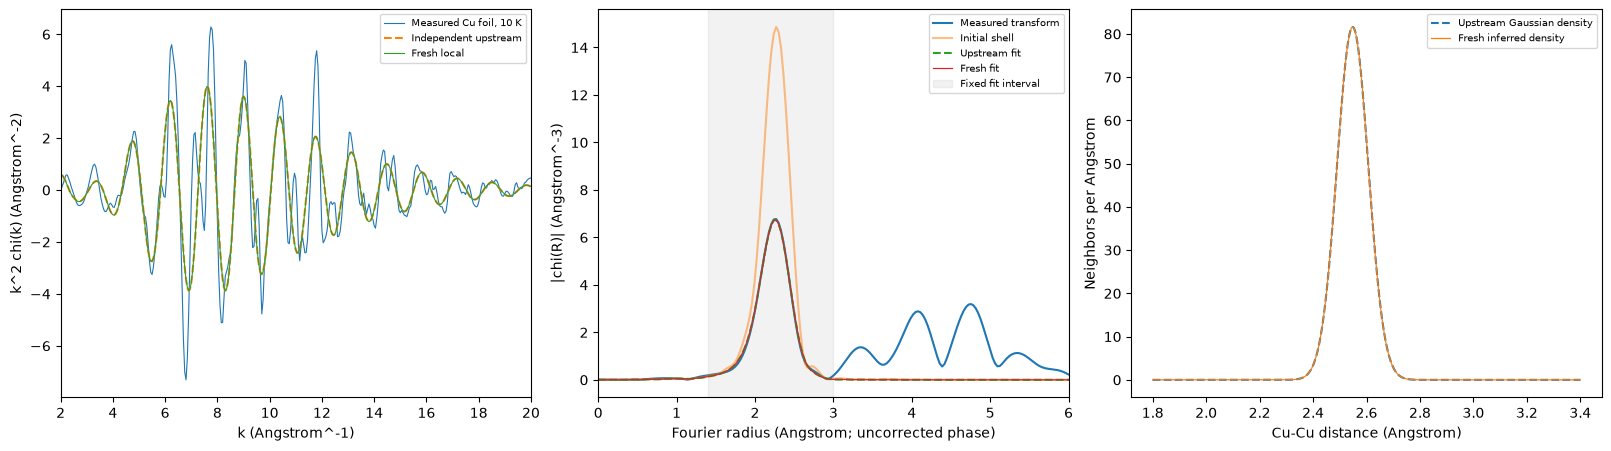

Parameter            Unit                  Initial      Upstream   Fresh local
amplitude            1                           1     0.9226437     0.9226437
edge correction      eV                          0     0.4210205     0.4210206
pair variance        Angstrom^2                  0   0.003440588   0.003440588
distance correction  Angstrom                    0  0.0004533642  0.0004533642


In [3]:
fig=comparisons(data,fresh,upstream)
fig.savefig(ROOT/'output/review.png',dpi=150)
plt.show()
print(f"{'Parameter':20s} {'Unit':15s} {'Initial':>13s} {'Upstream':>13s} {'Fresh local':>13s}")
for name,unit,i,u,v in zip(['amplitude','edge correction','pair variance','distance correction'],['1','eV','Angstrom^2','Angstrom'],INITIAL,upstream['parameters'][0],fresh['parameters'][0]):
    print(f'{name:20s} {unit:15s} {i:13.7g} {u:13.7g} {v:13.7g}')


### Metrics and interpretation
The R factor is the squared complex Fourier residual norm divided by the squared data norm in the fixed first-shell window. Profile NRMSE is RMS density difference divided by the oracle density dynamic range, and maximum parameter differences are normalized by(1,1 eV,0.01 Angstrom squared,0.1 Angstrom). The independently initialized oracle rerun differed by profile NRMSE1.0887209e-7 and normalized parameter error9.1112355e-6. Acceptance boundaries2e-5,2e-4,and0.00125 were frozen before judging the local result. This numerical comparison is to the standard inversion and does not invent independently measured truth.


In [4]:
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert code==0
print('Active inversion time (s):',info['seconds'])


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "profile_nrmse": 1.90277277251036e-10,
    "parameter_error": 1.6408396530387392e-08,
    "rfactor": 0.0012310909216522944
  },
  "thresholds": {
    "profile_nrmse": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "parameter_error": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "rfactor": {
      "comparison": "<=",
      "boundary": 0.00125
    }
  },
  "errors": []
}
Active inversion time (s): 0.011074200039729476


## 6. Conclusion

The cleaned explicit cumulant/complex-momentum/Fourier inversion agrees with an independent exact-source Larch fit and reconstructs a narrow first-neighbor Cu–Cu density from real10 K data. The first-shell forward R factor is approximately0.00123109. Gaussianity and coordination12 remain assumptions; the fit does not establish all higher shells, a unique distribution, or separate static/thermal disorder. Both the oracle values and local measurements are fresh task runs; no historical paper table is represented as a result of this computation.
